## California ZIP Code Boundaries
Load Census 2020 ZCTA boundaries, keep California, reproject to EPSG:3310, and match them to the CDI ZIP codes

In [1]:
from pathlib import Path
import pandas as pd
import geopandas as gpd

raw = Path("../data/raw")
clean = Path("../data/clean")

In [2]:
#load the national ZIP code shapes
zcta = gpd.read_file(raw / "cb_2020_us_zcta520_500k.zip")
print(zcta.crs)
print(len(zcta))
zcta.head()

EPSG:4269
33791


,ZCTA5CE20,AFFGEOID20,GEOID20,NAME20,LSAD20,ALAND20,AWATER20,geometry
0,15301,860Z200US15301,15301,15301,Z5,315861121,709775,"POLYGON ((-80.3686 40.21895, -80.35493 40.2440..."
1,15658,860Z200US15658,15658,15658,Z5,238683518,759690,"POLYGON ((-79.34323 40.17201, -79.3375 40.1777..."
2,15601,860Z200US15601,15601,15601,Z5,208874774,337008,"POLYGON ((-79.66911 40.28912, -79.6626 40.2858..."
3,17720,860Z200US17720,17720,17720,Z5,8797202,2822,"POLYGON ((-77.23026 41.18926, -77.2249 41.1904..."
4,18843,860Z200US18843,18843,18843,Z5,3620019,0,"POLYGON ((-75.90554 41.79017, -75.90545 41.792..."


In [3]:
#filter for california
zcta_ca = zcta[zcta["ZCTA5CE20"].between("90001", "96162")].copy()
print(len(zcta_ca))

1802


In [4]:
#load counties and reproject both layers to California Albers
counties = gpd.read_file(raw / "cb_2020_us_county_500k.zip")
ca_counties = counties[counties["STATEFP"] == "06"].copy()

zcta_ca = zcta_ca.to_crs(3310)
ca_counties = ca_counties.to_crs(3310)

print(len(ca_counties), zcta_ca.crs, ca_counties.crs)

58 EPSG:3310 EPSG:3310


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

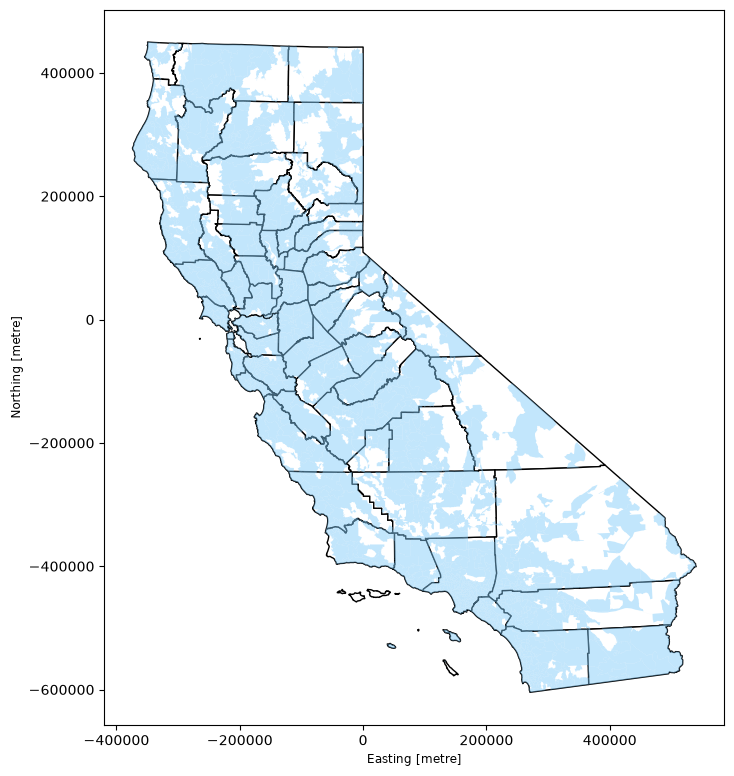

In [5]:
#plot to check
ax = ca_counties.plot(color = "white", edgecolor = "black", figsize = (8, 10))
zcta_ca.plot(ax = ax, color = "LightSkyBlue", alpha = 0.5)

In [6]:
#tidy columns
zcta_ca = zcta_ca.rename(columns = {"ZCTA5CE20": "zip", "ALAND20": "land_area_m2"})
zcta_ca = zcta_ca[["zip", "land_area_m2", "geometry"]]
zcta_ca.head()

,zip,land_area_m2,geometry
130,92040,174036781,"POLYGON ((280960.22 -557053.395, 281806.213 -5..."
131,96001,187530398,"POLYGON ((-214807.332 298429.235, -214712.701 ..."
132,90211,1813406,"POLYGON ((148569.357 -436909.878, 148624.183 -..."
133,90814,3451793,"POLYGON ((169760.599 -469846.101, 169808.994 -..."
134,92866,4937210,"POLYGON ((198452.878 -467451.209, 198499.645 -..."


In [7]:
#check how well cdi ZIPs match the shapes
cdi = pd.read_csv(clean / "cdi_nonrenewals_by_zip_year.csv", dtype = {"zip": str})

cdi_zips = cdi.groupby("zip")["up_for_renewal"].sum().reset_index()
match = cdi_zips.merge(zcta_ca[["zip"]], on = "zip", how = "left", indicator = True)

print(match["_merge"].value_counts())
unmatched = match[match["_merge"] == "left_only"]
print(f"Unmatched policies: {unmatched['up_for_renewal'].sum() / match['up_for_renewal'].sum():.2%}")

_merge
both          1798
left_only      859
right_only       0
Name: count, dtype: int64
Unmatched policies: 0.03%


In [8]:
#save
zcta_ca.to_file(clean / "ca_zip_boundaries.gpkg", driver = "GPKG")
ca_counties.to_file(clean / "ca_counties.gpkg", driver = "GPKG")

We kept 1,802 CA ZIP code shapes and all 58 counties, both reprojected to EPSG:3310. 859 CDI ZIP codes have no matching shape (holding only 0.03% of the policies), so they are likely to be PO boxes or business-only ZIP codes. We can drop them as they will not have any meaningful effect on the results.